# 🐎 Detector de atajadas – Rodeo chileno (FEROCHI)

Este notebook entrena un modelo que **reconoce el movimiento de la atajada** (el instante en que la collera detiene al novillo contra la quincha) y luego **puntúa** un video nuevo según la *Escala de Valoración de Atajadas* del compendio FEROCHI (§6.1):

| Tipo de atajada | Puntos buenos |
|---|---|
| Costilla libre (de íjar) | 4 |
| Paleta libre (de mitad) | 3 |
| Cogote libre | 2 |
| Envoltura | 0 |

**Cómo aprende el movimiento (no solo a ver animales):** el modelo es una red de video 3D (R(2+1)D‑18, preentrenada en Kinetics‑400 para reconocer *acciones humanas*). No mira fotos sueltas: recibe clips de 16 cuadros (~1,6 s) y sus convoluciones temporales aprenden la dinámica de la carrera — galope paralelo, aproximación, choque y frenado del novillo contra la quincha. Para cada instante del video entrega la probabilidad de que *ahí* ocurra la atajada.

**Etiquetas de entrenamiento:**
- **Momento**: se lee del nombre del archivo `..._X_SEGUNDOS.mp4` (solo para entrenar; luego el modelo encuentra el instante solo).
- **Tipo de atajada (para el puntaje)**: se lee del nombre de la **carpeta** (o del archivo) si contiene `costilla`/`ijar`, `paleta`/`mitad`, `cogote`, `envoltura`, o `4_puntos`, `3 pts`, etc. Si tus carpetas no indican el tipo, el modelo igual aprende a encontrar el momento, pero no podrá asignar puntaje (te lo avisará en la celda 2.2).

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4 o superior)*.

**Secciones:** 1 configuración · 2 entrenamiento · 3 analizar un video · 4 descargar el modelo entrenado · 5 API (recibe el video en bytes y responde puntaje, tipo de atajada y video procesado).

**Si reinicias la sesión y solo quieres analizar videos o levantar la API:** ejecuta la sección 1 completa (celdas 1.1 a 1.6) y luego la sección 3, 4 o 5.

## 1. Configuración y definiciones

In [ ]:
# 1.1 Verificar GPU
!nvidia-smi -L || echo "⚠ Sin GPU: el entrenamiento será muy lento. Cambia el tipo de entorno a GPU."

GPU 0: Tesla T4 (UUID: GPU-f90ffc50-4a1a-e97d-7185-b8ec9a7e7ebd)


In [ ]:
# 1.2 Parámetros generales
import os, re, io, sys, json, math, time, random, hashlib, subprocess, unicodedata, base64, tempfile, shutil, threading
from pathlib import Path
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------- Video / modelo ----------
TARGET_FPS = 10        # cuadros por segundo que ve el modelo
CLIP_LEN = 16          # cuadros por clip (16 a 10 fps = 1,6 s de movimiento)
FRAME_SIZE = 128       # tamaño al que se reduce cada cuadro
CROP_SIZE = 112        # recorte de entrada a la red
TYPE_RADIUS_S = 0.4    # radio (s) alrededor del momento usado para decidir el tipo de atajada

# ---------- Análisis de videos ----------
DET_THRESHOLD = 0.35   # probabilidad mínima para afirmar que hay atajada
HIGHLIGHT_S = 0.6      # segundos antes/después del momento que se marcan en rojo
SLOWMO_WINDOW_S = 1.5  # repetición en cámara lenta: ± segundos alrededor de la atajada
SLOWMO_FACTOR = 4      # 4 = velocidad 1/4
FREEZE_S = 1.5         # congelar el cuadro exacto de la atajada

KB_PATH = os.environ.get('KB_PATH', '')  # opcional: ruta al skills.md; si está vacío se busca en /content y en MyDrive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
VIDEO_EXT = {'.mp4', '.mov', '.avi', '.mkv', '.m4v', '.webm', '.mpg', '.mpeg', '.3gp', '.mts'}
from torch.utils.data import Dataset, DataLoader

# ---------- Datos ----------
DRIVE_FOLDER_ID = '14E-NpQvgnvw0AlMUgWjE6DYv2V2M7UhP'   # carpeta con los videos de entrenamiento
DATA_DIR = ''          # opcional: si ya tienes los videos en una ruta local/Drive, ponla aquí y no se descarga nada
LOCAL_VIDEOS = '/content/rodeo_videos'                 # copia local (lectura mucho más rápida que desde Drive)
WORK_DIR = '/content/rodeo_work'                       # caché de cuadros decodificados
OUTPUT_DIR = '/content/drive/MyDrive/rodeo_atajadas_modelo'  # modelo entrenado y resultados (queda en tu Drive)

# ---------- Entrenamiento ----------
SIGMA_S = 0.35         # tolerancia temporal de la etiqueta (s): el segundo del nombre es aproximado
PRETRAINED = True      # pesos Kinetics-400 (reconocimiento de acciones)
EPOCHS = 20
BATCH_SIZE = 16
SAMPLES_PER_VIDEO = 32 # clips aleatorios por video en cada época
LR_BACKBONE = 1e-4
LR_HEADS = 1e-3
TYPE_LOSS_WEIGHT = 0.5
VAL_FRACTION = 0.2
SEED = 42
NUM_WORKERS = 2
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
for d in (LOCAL_VIDEOS, WORK_DIR, f'{WORK_DIR}/cache', OUTPUT_DIR, f'{OUTPUT_DIR}/resultados'):
    os.makedirs(d, exist_ok=True)
CKPT_PATH = f'{OUTPUT_DIR}/atajada_r2plus1d.pt'
print('Dispositivo:', DEVICE)

Mounted at /content/drive
Dispositivo: cuda


In [ ]:
# 1.3 Base de conocimiento: escala de puntaje de atajadas (compendio FEROCHI §6.1)
REGLAS = {
    'costilla':  {'puntos': 4, 'nombre': 'Atajada de costilla libre (de íjar)'},
    'paleta':    {'puntos': 3, 'nombre': 'Atajada de paleta libre (de mitad)'},
    'cogote':    {'puntos': 2, 'nombre': 'Atajada de cogote libre'},
    'envoltura': {'puntos': 0, 'nombre': 'Envoltura (no se define la atajada)'},
}
TIPOS = list(REGLAS)
FUENTE_REGLAS = 'Compendio Normativo FEROCHI 2026-2027, §6.1 Escala de Valoración de Atajadas'

def sin_tildes(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

PALABRAS_TIPO = {
    'costilla':  ['costilla', 'ijar'],
    'paleta':    ['paleta', 'mitad'],
    'cogote':    ['cogote', 'pescuezo'],
    'envoltura': ['envoltura', 'envuelta', 'envolvio'],
}

def cargar_reglas_md(path):
    # Lee líneas tipo '**Atajada de Costilla Libre (de íjar)**: 4 puntos buenos.' y actualiza REGLAS
    texto = Path(path).read_text(encoding='utf-8')
    n = 0
    for m in re.finditer(r'\*\*([^*]+)\*\*\s*:\s*(\d+)\s*punto', texto):
        etiqueta, pts = m.group(1).strip(), int(m.group(2))
        e = sin_tildes(etiqueta).lower()
        for tipo, claves in PALABRAS_TIPO.items():
            if any(k in e for k in claves):
                REGLAS[tipo] = {'puntos': pts, 'nombre': etiqueta}
                n += 1
                break
    return n

_kb = KB_PATH or next((p for p in ['/content/skills.md', '/content/drive/MyDrive/skills.md'] if os.path.exists(p)), '')
if _kb and os.path.exists(_kb):
    print(f'Base de conocimiento leída de {_kb}: {cargar_reglas_md(_kb)} reglas de atajada.')
else:
    print('Usando la escala de atajadas del compendio incluida en el notebook.')
for t in TIPOS:
    print(f"  {REGLAS[t]['nombre']:<40} -> {REGLAS[t]['puntos']} pts")

Usando la escala de atajadas del compendio incluida en el notebook.
  Atajada de costilla libre (de íjar)      -> 4 pts
  Atajada de paleta libre (de mitad)       -> 3 pts
  Atajada de cogote libre                  -> 2 pts
  Envoltura (no se define la atajada)      -> 0 pts


In [ ]:
# 1.4 Utilidades de video
MEAN = np.array([0.43216, 0.394666, 0.37645], np.float32)   # normalización Kinetics
STD = np.array([0.22803, 0.22145, 0.216989], np.float32)

def leer_video(path, fps_obj=None, size=None):
    # Devuelve cuadros RGB (N,size,size,3) muestreados a fps_obj, sus tiempos (s) y la duración total
    fps_obj = fps_obj or TARGET_FPS; size = size or FRAME_SIZE
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps < 1:
        fps = 30.0
    frames, times = [], []
    i, prox, paso = 0, 0.0, 1.0 / fps_obj
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        t = i / fps
        if t + 1e-6 >= prox:
            fr = cv2.resize(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_AREA)
            frames.append(fr); times.append(t)
            while prox <= t + 1e-6:
                prox += paso
        i += 1
    cap.release()
    if not frames:
        return np.zeros((0, size, size, 3), np.uint8), np.zeros(0, np.float32), 0.0
    return np.stack(frames), np.array(times, np.float32), i / fps

def indices_clip(n, c, L=None):
    # índices de un clip de L cuadros centrado en c (se repiten los bordes)
    L = L or CLIP_LEN
    return np.clip(np.arange(c - L // 2, c - L // 2 + L), 0, n - 1)

def preparar_clip(clip, train=False):
    # (L,H,W,3) uint8 -> tensor (3,L,CROP,CROP) normalizado; con aumentos si train
    L, H, W, _ = clip.shape
    if train:
        y0 = np.random.randint(0, H - CROP_SIZE + 1); x0 = np.random.randint(0, W - CROP_SIZE + 1)
    else:
        y0 = (H - CROP_SIZE) // 2; x0 = (W - CROP_SIZE) // 2
    x = clip[:, y0:y0 + CROP_SIZE, x0:x0 + CROP_SIZE].astype(np.float32) / 255.0
    if train:
        if np.random.rand() < 0.5:          # atajadas hacia ambos lados de la medialuna
            x = x[:, :, ::-1]
        x = np.clip(x * np.random.uniform(0.8, 1.2) + np.random.uniform(-0.08, 0.08), 0, 1)
    x = (x - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(3, 0, 1, 2)))

In [ ]:
# 1.5 Modelo: red de video 3D que aprende el movimiento
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights

class AtajadaNet(nn.Module):
    # det  -> probabilidad de que el centro del clip sea el instante de la atajada
    # tipo -> costilla / paleta / cogote / envoltura
    def __init__(self, n_tipos, pretrained=True):
        super().__init__()
        self.backbone = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1 if pretrained else None)
        feat = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.drop = nn.Dropout(0.4)
        self.det = nn.Linear(feat, 1)
        self.tipo = nn.Linear(feat, n_tipos)

    def forward(self, x):
        f = self.drop(self.backbone(x))
        return self.det(f).squeeze(1), self.tipo(f)

@torch.no_grad()
def curva_atajada(model, frames, times, stride=1, batch=32):
    # Recorre todo el video con una ventana deslizante y devuelve la probabilidad de atajada en cada instante
    model.eval()
    n = len(frames)
    centros = np.arange(0, n, stride)
    P, T = [], []
    for s in range(0, len(centros), batch):
        x = torch.stack([preparar_clip(np.asarray(frames[indices_clip(n, c)])) for c in centros[s:s + batch]]).to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            det, tip = model(x)
        P.append(torch.sigmoid(det.float()).cpu().numpy())
        T.append(torch.softmax(tip.float(), 1).cpu().numpy())
    return times[centros], np.concatenate(P), np.concatenate(T)

def suavizar(p, k=3):
    if len(p) < k:
        return p
    return np.convolve(np.pad(p, k // 2, mode='edge'), np.ones(k) / k, mode='valid')

def localizar(ts, p, tp, radio=None):
    # Momento de máxima probabilidad + probabilidades de tipo promediadas alrededor de ese momento
    radio = radio or TYPE_RADIUS_S
    ps = suavizar(p)
    j = int(np.argmax(ps))
    cerca = np.abs(ts - ts[j]) <= radio
    w = ps[cerca][:, None]
    tipo_prob = (tp[cerca] * w).sum(0) / max(float(w.sum()), 1e-6)
    return {'t': float(ts[j]), 'prob': float(ps[j]), 'tipo_prob': tipo_prob, 'curva': ps}

def cargar_modelo(ckpt_path):
    # Carga el modelo entrenado y la configuración con que se entrenó (tipos, reglas, fps, tamaños)
    global model, TIPOS, TIPOS_ENTRENADOS, TARGET_FPS, CLIP_LEN, FRAME_SIZE, CROP_SIZE
    ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    TIPOS = ck['tipos']; TIPOS_ENTRENADOS = ck['tipos_entrenados']; REGLAS.update(ck['reglas'])
    TARGET_FPS, CLIP_LEN, FRAME_SIZE, CROP_SIZE = (ck['config'][k] for k in ('TARGET_FPS', 'CLIP_LEN', 'FRAME_SIZE', 'CROP_SIZE'))
    model = AtajadaNet(len(TIPOS), pretrained=False).to(DEVICE)
    model.load_state_dict(ck['state_dict']); model.eval()
    return ck

In [ ]:
# 1.6 Análisis de un video: puntaje + video anotado con el momento de la atajada
import matplotlib.pyplot as plt

def _txt(img, texto, org, escala, color, grosor=2, fondo=(0, 0, 0)):
    texto = sin_tildes(texto)
    (w, h), b = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, grosor)
    x, y = org
    cv2.rectangle(img, (x - 6, y - h - 8), (x + w + 6, y + b + 4), fondo, -1)
    cv2.putText(img, texto, (x, y), cv2.FONT_HERSHEY_SIMPLEX, escala, color, grosor, cv2.LINE_AA)

def _franja(W, alto, ts, curva, dur, t_at):
    img = np.full((alto, W, 3), 30, np.uint8)
    X = lambda t: int(np.clip(t / max(dur, 1e-6) * (W - 1), 0, W - 1))
    Y = lambda p: int(alto - 8 - p * (alto - 28))
    cv2.line(img, (0, Y(DET_THRESHOLD)), (W - 1, Y(DET_THRESHOLD)), (90, 90, 90), 1)
    pts = np.array([[X(t), Y(p)] for t, p in zip(ts, curva)], np.int32)
    if len(pts) > 1:
        cv2.polylines(img, [pts], False, (0, 200, 255), 2, cv2.LINE_AA)
    if t_at is not None:
        cv2.line(img, (X(t_at), 0), (X(t_at), alto - 1), (0, 0, 255), 2)
    _txt(img, 'Prob. de atajada', (8, 18), 0.45, (220, 220, 220), 1, fondo=(30, 30, 30))
    return img, X

def anotar_video(path, res, out_path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if fps and fps == fps and fps >= 1 else 30.0
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    esc = max(W / 1280, 0.45)
    alto_f = max(int(90 * esc), 60)
    t_at = res['t'] if res['detectada'] else None
    franja, X = _franja(W, alto_f, res['ts'], res['curva'], res['duracion'], t_at)
    if not res['detectada']:
        titulo = 'Sin atajada clara'
    elif res['puntos'] is None:
        titulo = 'Atajada detectada (tipo no entrenado)'
    else:
        titulo = f"{res['nombre']}: {res['puntos']} pts"
    g = max(1, int(2 * esc))

    def componer(fr, t, repeticion=False):
        img = fr.copy()
        cerca = res['detectada'] and abs(t - res['t']) <= HIGHLIGHT_S
        if cerca:
            cv2.rectangle(img, (0, 0), (W - 1, H - 1), (0, 0, 255), max(4, int(12 * esc)))
            _txt(img, f"ATAJADA  t = {res['t']:.1f} s", (int(20 * esc), H - int(30 * esc)), 1.3 * esc, (255, 255, 255), max(2, int(3 * esc)), fondo=(0, 0, 200))
        _txt(img, titulo, (int(20 * esc), int(45 * esc)), 0.9 * esc, (255, 255, 255), g)
        _txt(img, f't = {t:5.2f} s', (int(20 * esc), int(90 * esc)), 0.7 * esc, (200, 200, 200), g)
        if repeticion:
            _txt(img, f'REPETICION 1/{SLOWMO_FACTOR}', (W - int(330 * esc), int(45 * esc)), 0.8 * esc, (0, 255, 255), g)
        f = franja.copy()
        cv2.line(f, (X(t), 0), (X(t), alto_f - 1), (255, 255, 255), 1)
        return np.vstack([img, f])

    tmp = out_path + '.tmp.mp4'
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H + alto_f))
    clave, mejor, i = None, 1e9, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        t = i / fps
        lienzo = componer(fr, t)
        vw.write(lienzo)
        if t_at is not None and abs(t - t_at) < mejor:
            mejor, clave = abs(t - t_at), lienzo.copy()
        i += 1
    # Repetición en cámara lenta con cuadro congelado en el instante exacto
    if t_at is not None:
        j = max(0, int((t_at - SLOWMO_WINDOW_S) * fps))
        cap.set(cv2.CAP_PROP_POS_FRAMES, j)
        congelado = False
        while j / fps <= t_at + SLOWMO_WINDOW_S:
            ok, fr = cap.read()
            if not ok:
                break
            lienzo = componer(fr, j / fps, repeticion=True)
            reps = SLOWMO_FACTOR
            if not congelado and j / fps >= t_at - 0.5 / fps:
                reps += int(FREEZE_S * fps); congelado = True
            for _ in range(reps):
                vw.write(lienzo)
            j += 1
    cap.release(); vw.release()
    try:   # H.264 para que se vea en el navegador
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', tmp, '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2',
                        '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', '-crf', '23', out_path], check=True)
        os.remove(tmp)
    except Exception as e:
        print('ffmpeg no disponible, se deja el video en mp4v:', e)
        os.replace(tmp, out_path)
    return clave

def analizar_video(path, mostrar=True, out_dir=None):
    frames, times, dur = leer_video(path)
    if len(frames) == 0:
        raise ValueError(f'No se pudo leer el video: {path}')
    ts, p, tp = curva_atajada(model, frames, times)
    loc = localizar(ts, p, tp)
    detectada = loc['prob'] >= DET_THRESHOLD
    tipo, conf_tipo, probs_tipo = None, None, {}
    if TIPOS_ENTRENADOS:
        idx = [TIPOS.index(t) for t in TIPOS_ENTRENADOS]
        pt = loc['tipo_prob'][idx]; pt = pt / max(pt.sum(), 1e-9)
        probs_tipo = {t: float(v) for t, v in zip(TIPOS_ENTRENADOS, pt)}
        tipo = max(probs_tipo, key=probs_tipo.get); conf_tipo = probs_tipo[tipo]
    res = {
        'video': str(path), 'duracion': float(dur), 'detectada': bool(detectada),
        't': loc['t'], 'prob': loc['prob'], 'ts': ts, 'curva': loc['curva'],
        'tipo': tipo if detectada else None, 'conf_tipo': conf_tipo, 'probs_tipo': probs_tipo,
        'nombre': REGLAS[tipo]['nombre'] if (detectada and tipo) else None,
        'puntos': (REGLAS[tipo]['puntos'] if tipo else None) if detectada else 0,
    }
    base = Path(path).stem
    out_dir = out_dir or f'{OUTPUT_DIR}/resultados'
    os.makedirs(out_dir, exist_ok=True)
    out_video = f'{out_dir}/{base}_ANOTADO.mp4'
    clave = anotar_video(path, res, out_video)

    # Justificación
    lineas = []
    if not detectada:
        lineas.append(f"No se detectó una atajada clara (máxima probabilidad {loc['prob']:.0%} < umbral {DET_THRESHOLD:.0%}).")
        lineas.append('Puntaje asignado por atajada: 0.')
    else:
        lineas.append(f"Momento de la atajada: {res['t']:.1f} s (confianza de detección {res['prob']:.0%}).")
        if tipo:
            lineas.append(f"Clasificación: {res['nombre']} -> {res['puntos']} puntos buenos (confianza {conf_tipo:.0%}).")
            lineas.append(f"Fundamento: {FUENTE_REGLAS}: «{res['nombre']}» = {res['puntos']} puntos buenos.")
            lineas.append('Probabilidad por tipo: ' + ', '.join(f"{t} {v:.0%}" for t, v in sorted(probs_tipo.items(), key=lambda kv: -kv[1])))
            if conf_tipo < 0.5:
                lineas.append('⚠ Confianza baja en el tipo de atajada: revisa la repetición en cámara lenta.')
        else:
            lineas.append('El modelo no fue entrenado con el tipo de atajada (carpetas sin costilla/paleta/cogote/envoltura), no puede asignar puntaje.')
    lineas.append('Nota: se evalúa solo la atajada; la salida del apiñadero (+1) y las faltas (tijera, ayuda, etc.) no se califican aquí.')
    res['justificacion'] = '\n'.join(lineas)

    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(ts, loc['curva'], color='tab:orange', label='prob. de atajada')
    ax.axhline(DET_THRESHOLD, color='gray', ls='--', lw=1, label='umbral')
    if detectada:
        ax.axvline(res['t'], color='red', lw=2, label=f"atajada {res['t']:.1f} s")
        ax.axvspan(res['t'] - HIGHLIGHT_S, res['t'] + HIGHLIGHT_S, color='red', alpha=0.12)
    ax.set_xlabel('segundos'); ax.set_ylim(0, 1); ax.legend(loc='upper left'); ax.set_title(base)
    fig.tight_layout(); fig.savefig(f'{out_dir}/{base}_curva.png', dpi=110)
    img_path = None
    if clave is not None:
        img_path = f'{out_dir}/{base}_momento_atajada.jpg'
        cv2.imwrite(img_path, clave)
    res['archivos'] = {'video': out_video, 'imagen': img_path, 'curva': f'{out_dir}/{base}_curva.png'}
    guardable = {k: v for k, v in res.items() if k not in ('ts', 'curva')}
    Path(f'{out_dir}/{base}_resultado.json').write_text(json.dumps(guardable, ensure_ascii=False, indent=2))

    if mostrar:
        from IPython.display import display, HTML, Image as IPImage
        print('=' * 70)
        print(f"PUNTAJE DE LA ATAJADA: {res['puntos'] if res['puntos'] is not None else 's/d'}")
        print('=' * 70)
        print(res['justificacion'])
        plt.show()
        if clave is not None:
            print('Cuadro exacto de la atajada:')
            display(IPImage(filename=f'{out_dir}/{base}_momento_atajada.jpg', width=720))
        if os.path.getsize(out_video) < 45 * 1024 * 1024:
            b64 = base64.b64encode(open(out_video, 'rb').read()).decode()
            display(HTML(f'<video width="760" controls src="data:video/mp4;base64,{b64}"></video>'))
        else:
            print('Video anotado (muy pesado para mostrarlo aquí):', out_video)
        print('Archivos guardados en:', out_dir)
    else:
        plt.close(fig)
    return res

## 2. Entrenamiento
Ejecuta esta sección una vez (o cuando agregues videos nuevos a la carpeta).

In [ ]:
# 2.1 Descargar los videos de la carpeta de Drive (incluye subcarpetas; respeta sus nombres)
def descargar_carpeta_drive(folder_id, destino):
    from google.colab import auth
    auth.authenticate_user()
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    svc = build('drive', 'v3', cache_discovery=False)
    cont = {'total': 0, 'nuevos': 0}

    def listar(fid):
        token = None
        while True:
            r = svc.files().list(q=f"'{fid}' in parents and trashed = false",
                                 fields='nextPageToken, files(id, name, mimeType, size)', pageSize=1000,
                                 supportsAllDrives=True, includeItemsFromAllDrives=True, pageToken=token).execute()
            yield from r.get('files', [])
            token = r.get('nextPageToken')
            if not token:
                break

    def recorrer(fid, ruta):
        os.makedirs(ruta, exist_ok=True)
        for f in listar(fid):
            nombre = f['name'].replace('/', '_')
            if f['mimeType'] == 'application/vnd.google-apps.folder':
                recorrer(f['id'], os.path.join(ruta, nombre)); continue
            if Path(nombre).suffix.lower() not in VIDEO_EXT:
                continue
            cont['total'] += 1
            dst = os.path.join(ruta, nombre)
            if os.path.exists(dst) and os.path.getsize(dst) == int(f.get('size', -1)):
                continue
            req = svc.files().get_media(fileId=f['id'], supportsAllDrives=True)
            with io.FileIO(dst, 'wb') as fh:
                dl = MediaIoBaseDownload(fh, req, chunksize=32 * 1024 * 1024)
                listo = False
                while not listo:
                    _, listo = dl.next_chunk()
            cont['nuevos'] += 1
            print('  descargado:', os.path.relpath(dst, destino))

    recorrer(folder_id, destino)
    print(f"{cont['total']} videos en la carpeta ({cont['nuevos']} descargados ahora).")

if DATA_DIR:
    VIDEOS_ROOT = DATA_DIR
else:
    descargar_carpeta_drive(DRIVE_FOLDER_ID, LOCAL_VIDEOS)
    VIDEOS_ROOT = LOCAL_VIDEOS
print('Videos en:', VIDEOS_ROOT)

  descargado: 4 PUNTOS/32-4ptos-2s.mp4
  descargado: 4 PUNTOS/28-4ptos-2s.mp4
  descargado: 4 PUNTOS/27-4ptos-2s.mp4
  descargado: 4 PUNTOS/24-4ptos-3s.mp4
  descargado: 4 PUNTOS/22-4ptos-2s.mp4
  descargado: 4 PUNTOS/21-4ptos-3s.mp4
  descargado: 4 PUNTOS/20-4ptos-3s.mp4
  descargado: 4 PUNTOS/19-4ptos-1s.mp4
  descargado: 4 PUNTOS/15-4pts-6s.mp4
  descargado: 4 PUNTOS/14-4pts-2s.mp4
  descargado: 4 PUNTOS/07-4pts-3s.mp4
  descargado: 4 PUNTOS/04-4pts-1s.mp4
  descargado: 4 PUNTOS/CASO 39 - 4ptos.09_4_seg.mp4
  descargado: 4 PUNTOS/CASO 31 - 4pto.01_2_seg.mp4
  descargado: 4 PUNTOS/CASO 37 - 4ptos.07_4_seg.mp4
  descargado: 4 PUNTOS/CASO 34 - 4ptos.04_2_seg.mp4
  descargado: 4 PUNTOS/CASO 35 - 4ptos.05_3_seg.mp4
  descargado: 4 PUNTOS/CASO 38 - 4ptos.08_3_seg.mp4
  descargado: 4 PUNTOS/CASO 33 - 4ptos.03_4_seg.mp4
  descargado: 4 PUNTOS/CASO 32 -4ptos.02_3_seg.mp4
  descargado: 4 PUNTOS/CASO 40 - 4ptos.10_1_seg.mp4
  descargado: 4 PUNTOS/CASO 36 - 4ptos.06_4_seg.mp4
  descargado: 4 PU

In [ ]:
# 2.2 Etiquetas: segundo de la atajada (nombre del archivo) y tipo (nombre de carpeta/archivo)
from collections import Counter
PATRON_SEG = re.compile(r'_(\d+(?:[.,]\d+)?)_SEGUNDOS?', re.IGNORECASE)
PATRON_PTS = re.compile(r'(?<!\d)([0234])\s*_?\s*(?:pts?|puntos?)(?![a-z])')
PTS_A_TIPO = {REGLAS[t]['puntos']: t for t in TIPOS}

def inferir_tipo(ruta_rel):
    texto = sin_tildes(PATRON_SEG.sub(' ', ruta_rel)).lower()
    for tipo, claves in PALABRAS_TIPO.items():
        if any(k in texto for k in claves):
            return tipo
    m = PATRON_PTS.search(texto)
    return PTS_A_TIPO.get(int(m.group(1))) if m else None

items = []
for p in sorted(Path(VIDEOS_ROOT).rglob('*')):
    if not p.is_file() or p.suffix.lower() not in VIDEO_EXT:
        continue
    m = PATRON_SEG.search(p.stem)
    if not m:
        print('⚠ Sin "_X_SEGUNDOS" en el nombre, se omite:', p.name)
        continue
    rel = str(p.relative_to(VIDEOS_ROOT))
    items.append({'path': str(p), 'rel': rel, 't': float(m.group(1).replace(',', '.')), 'tipo': inferir_tipo(rel)})

print(f'{len(items)} videos etiquetados.')
print('Por tipo de atajada:', dict(Counter(it['tipo'] or 'sin tipo' for it in items)))
for it in items[:10]:
    print(f"  {it['rel']:<60} t={it['t']:>6.2f}s  tipo={it['tipo']}")
if not any(it['tipo'] for it in items):
    print('\n⚠ Ninguna carpeta/archivo indica el tipo de atajada. El modelo aprenderá a ENCONTRAR la atajada, '
          'pero no podrá asignar el puntaje. Organiza los videos en carpetas "costilla", "paleta", "cogote" y "envoltura" '
          '(o agrega esa palabra al nombre del archivo) y vuelve a ejecutar desde 2.1.')
assert items, 'No se encontraron videos con el patrón _X_SEGUNDOS.'

⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 18-2ptos-2s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 01-3pts-3seg.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 02-3pts-5s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 03-3pts-6s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 05-3pts-4s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 06-3pts-9s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 08-3pts-4s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 09-3pts-3s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 10-3pts-4s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 11-3pts-3s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 12-3pts-4s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 13-3pts-3s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 16-3ptos-2s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 17-3ptos-4s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 23-3ptos-3s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 25-3ptos-3s.mp4
⚠ Sin "_X_SEGUNDOS" en el nombre, se omite: 26-3p

In [ ]:
# 2.3 Decodificar cada video una sola vez (caché en disco)
from tqdm.auto import tqdm

def cachear(it):
    st = os.stat(it['path'])
    key = hashlib.md5(f"{it['path']}|{st.st_size}|{int(st.st_mtime)}|{TARGET_FPS}|{FRAME_SIZE}".encode()).hexdigest()[:16]
    fpath, tpath, mpath = (f'{WORK_DIR}/cache/{key}_{s}' for s in ('frames.npy', 'times.npy', 'meta.json'))
    if not (os.path.exists(fpath) and os.path.exists(tpath) and os.path.exists(mpath)):
        frames, times, dur = leer_video(it['path'])
        np.save(fpath, frames); np.save(tpath, times)
        Path(mpath).write_text(json.dumps({'duracion': dur}))
    it['frames'], it['times'] = fpath, tpath
    it['duracion'] = json.loads(Path(mpath).read_text())['duracion']
    return it

validos = []
for it in tqdm(items, desc='Decodificando'):
    cachear(it)
    n = len(np.load(it['times']))
    if n < 2:
        print('⚠ Video ilegible, se omite:', it['rel']); continue
    if it['t'] > it['duracion'] + 0.5:
        print(f"⚠ {it['rel']}: la atajada ({it['t']}s) está después del final ({it['duracion']:.1f}s), se omite."); continue
    validos.append(it)
items = validos
print(f'{len(items)} videos listos para entrenar.')

Decodificando:   0%|          | 0/70 [00:00<?, ?it/s]

70 videos listos para entrenar.


In [ ]:
# 2.4 Separar entrenamiento / validación (por video, estratificado por tipo)
rng = random.Random(SEED)
grupos = {}
for it in items:
    grupos.setdefault(it['tipo'] or 'sin_tipo', []).append(it)
train_items, val_items = [], []
for g in grupos.values():
    rng.shuffle(g)
    k = int(round(len(g) * VAL_FRACTION)) if len(g) >= 3 else 0
    val_items += g[:k]; train_items += g[k:]
if len(val_items) == 0:
    print('⚠ Muy pocos videos para separar validación: se valida sobre los mismos videos de entrenamiento (métrica optimista).')
    val_items = list(train_items)
TIPOS_ENTRENADOS = sorted({it['tipo'] for it in train_items if it['tipo']}, key=TIPOS.index)
print(f'Entrenamiento: {len(train_items)} videos | Validación: {len(val_items)} videos')
print('Tipos que aprenderá a clasificar:', TIPOS_ENTRENADOS or 'ninguno')

Entrenamiento: 56 videos | Validación: 14 videos
Tipos que aprenderá a clasificar: ['costilla', 'paleta', 'cogote']


In [ ]:
# 2.5 Dataset: clips cerca del momento (positivos), cerca pero no en él (negativos difíciles) y al azar
class ClipsAtajada(Dataset):
    def __init__(self, items, muestras_por_video):
        self.items, self.m, self._cache = items, muestras_por_video, {}

    def _datos(self, i):
        if i not in self._cache:
            it = self.items[i]
            self._cache[i] = (np.load(it['frames'], mmap_mode='r'), np.load(it['times']))
        return self._cache[i]

    def __len__(self):
        return len(self.items) * self.m

    def __getitem__(self, k):
        i = k // self.m
        it = self.items[i]
        frames, times = self._datos(i)
        n, ta = len(frames), it['t']
        r = np.random.rand()
        if r < 0.45:
            tc = ta + np.random.uniform(-0.5, 0.5)                              # en la atajada
        elif r < 0.7:
            tc = ta + np.random.choice([-1, 1]) * np.random.uniform(0.6, 2.5)   # justo antes / después
        else:
            tc = np.random.uniform(times[0], times[-1])                          # cualquier momento
        c = int(np.clip(np.searchsorted(times, tc), 0, n - 1))
        d = float(times[c] - ta)
        y = math.exp(-0.5 * (d / SIGMA_S) ** 2)    # etiqueta suave: 1 en el instante, decae con la distancia
        tipo = TIPOS.index(it['tipo']) if (it['tipo'] and abs(d) <= TYPE_RADIUS_S) else -100
        clip = np.asarray(frames[indices_clip(n, c)])
        return preparar_clip(clip, train=True), torch.tensor(y, dtype=torch.float32), torch.tensor(tipo)

ds_train = ClipsAtajada(train_items, SAMPLES_PER_VIDEO)
x, y, tp = ds_train[0]
print('Clip de entrada:', tuple(x.shape), '(canales, cuadros, alto, ancho)')

Clip de entrada: (3, 16, 112, 112) (canales, cuadros, alto, ancho)


In [ ]:
# 2.6 Entrenar
# Accuracy reportado en cada época:
#   train acc det  : % de clips de entrenamiento bien clasificados como "atajada / no atajada"
#   train acc tipo : % de clips cerca de la atajada con el tipo (costilla/paleta/cogote/envoltura) correcto
#   val acc momento: % de videos de validación donde el momento detectado está a <= TOLERANCIA_ACC_S del real
#   val acc tipo   : % de videos de validación con el tipo de atajada correcto
#   val acc global : % de videos con momento Y tipo correctos (= puntaje correcto). Con este se elige el mejor modelo.
TOLERANCIA_ACC_S = 1.0

def evaluar(model, items_eval):
    filas = []
    for it in items_eval:
        frames = np.load(it['frames'], mmap_mode='r'); times = np.load(it['times'])
        ts, p, tp = curva_atajada(model, frames, times)
        loc = localizar(ts, p, tp)
        pred_tipo = None
        if TIPOS_ENTRENADOS:
            idx = [TIPOS.index(t) for t in TIPOS_ENTRENADOS]
            pred_tipo = TIPOS_ENTRENADOS[int(np.argmax(loc['tipo_prob'][idx]))]
        filas.append({'video': it['rel'], 't_real': it['t'], 't_pred': loc['t'], 'error_s': abs(loc['t'] - it['t']),
                      'prob': loc['prob'], 'tipo_real': it['tipo'], 'tipo_pred': pred_tipo})
    err = np.array([f['error_s'] for f in filas])
    con_tipo = [f for f in filas if f['tipo_real']]
    acc = np.mean([f['tipo_real'] == f['tipo_pred'] for f in con_tipo]) if con_tipo else float('nan')
    # accuracy global: momento a <= TOLERANCIA_ACC_S del real Y tipo correcto (si el video tiene tipo) -> puntaje correcto
    ok = [f['error_s'] <= TOLERANCIA_ACC_S and (f['tipo_real'] is None or f['tipo_real'] == f['tipo_pred']) for f in filas]
    return {'mae': float(err.mean()), 'dentro_0.5s': float((err <= 0.5).mean()), 'dentro_1s': float((err <= 1.0).mean()),
            'acc_momento': float((err <= TOLERANCIA_ACC_S).mean()), 'acc_tipo': float(acc),
            'acc_global': float(np.mean(ok)), 'filas': filas}

model = AtajadaNet(len(TIPOS), PRETRAINED).to(DEVICE)
for name, prm in model.backbone.named_parameters():      # capas iniciales congeladas: pocos datos
    if name.startswith(('stem', 'layer1')):
        prm.requires_grad = False
opt = torch.optim.AdamW([
    {'params': [p_ for p_ in model.backbone.parameters() if p_.requires_grad], 'lr': LR_BACKBONE},
    {'params': list(model.det.parameters()) + list(model.tipo.parameters()), 'lr': LR_HEADS},
], weight_decay=1e-4)
dl = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                drop_last=len(ds_train) > BATCH_SIZE, pin_memory=(DEVICE == 'cuda'))
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, EPOCHS * len(dl)))
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))

historial, mejor = [], None
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); perd = []
    ok_det = n_det = ok_tipo = n_tipo = 0
    for x, y, tp in dl:
        x, y, tp = x.to(DEVICE, non_blocking=True), y.to(DEVICE), tp.to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            det, tip = model(x)
        loss = F.binary_cross_entropy_with_logits(det.float(), y)
        if (tp >= 0).any():
            loss = loss + TYPE_LOSS_WEIGHT * F.cross_entropy(tip.float(), tp, ignore_index=-100)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        perd.append(loss.item())
        with torch.no_grad():
            ok_det += ((det.float() > 0) == (y >= 0.5)).sum().item(); n_det += y.numel()
            m = tp >= 0
            if m.any():
                ok_tipo += (tip.float()[m].argmax(1) == tp[m]).sum().item(); n_tipo += int(m.sum().item())
    ev = evaluar(model, val_items)
    train_acc_det = ok_det / max(n_det, 1)
    train_acc_tipo = ok_tipo / n_tipo if n_tipo else float('nan')
    historial.append({'epoca': ep, 'loss': float(np.mean(perd)), 'train_acc_det': train_acc_det,
                      'train_acc_tipo': train_acc_tipo, **{k: v for k, v in ev.items() if k != 'filas'}})
    pct = lambda v: ' s/d' if v != v else f'{v:4.0%}'
    print(f"Época {ep:2d} | loss {np.mean(perd):.4f} | train acc det {pct(train_acc_det)} tipo {pct(train_acc_tipo)} | "
          f"val acc momento {pct(ev['acc_momento'])} tipo {pct(ev['acc_tipo'])} GLOBAL {pct(ev['acc_global'])} | "
          f"error medio {ev['mae']:.2f}s | {time.time() - t0:.0f}s")
    puntaje = (-ev['acc_global'], ev['mae'])
    if mejor is None or puntaje < mejor:
        mejor = puntaje
        torch.save({'state_dict': model.state_dict(), 'tipos': TIPOS, 'tipos_entrenados': TIPOS_ENTRENADOS,
                    'reglas': REGLAS, 'config': {'TARGET_FPS': TARGET_FPS, 'CLIP_LEN': CLIP_LEN,
                                                 'FRAME_SIZE': FRAME_SIZE, 'CROP_SIZE': CROP_SIZE},
                    'metricas': historial[-1]}, CKPT_PATH)
        print('   ✓ mejor modelo guardado en', CKPT_PATH)

Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth


100%|██████████| 120M/120M [00:00<00:00, 151MB/s]


Época  1 | loss 0.6675 | train acc det  78% tipo  84% | val acc momento 100% tipo  50% GLOBAL  50% | error medio 0.28s | 75s
   ✓ mejor modelo guardado en /content/drive/MyDrive/rodeo_atajadas_modelo/atajada_r2plus1d.pt
Época  2 | loss 0.3953 | train acc det  88% tipo  97% | val acc momento 100% tipo  43% GLOBAL  43% | error medio 0.24s | 84s
Época  3 | loss 0.3670 | train acc det  91% tipo  98% | val acc momento 100% tipo  50% GLOBAL  50% | error medio 0.27s | 83s
   ✓ mejor modelo guardado en /content/drive/MyDrive/rodeo_atajadas_modelo/atajada_r2plus1d.pt
Época  4 | loss 0.3480 | train acc det  92% tipo  99% | val acc momento 100% tipo  43% GLOBAL  43% | error medio 0.24s | 83s
Época  5 | loss 0.3216 | train acc det  93% tipo 100% | val acc momento 100% tipo  43% GLOBAL  43% | error medio 0.23s | 83s
Época  6 | loss 0.2974 | train acc det  94% tipo 100% | val acc momento 100% tipo  43% GLOBAL  43% | error medio 0.23s | 84s
Época  7 | loss 0.2873 | train acc det  94% tipo 100% | val 

ACCURACY GLOBAL (momento ±1s y tipo correctos = puntaje correcto): 50%
Accuracy del momento: 100% | accuracy del tipo: 50% | error medio: 0.27 s | dentro de 0,5 s: 93%

Matriz de confusión del tipo (filas = real, columnas = predicho):
               costilla     paleta     cogote
costilla              2          4          0
paleta                2          4          0
cogote                1          0          1

2 PUNTOS/CASO 08 - 2 PUNTOS BUENOS_8_SEGUNDOS.mp4       real   8.00s  pred   7.60s  err  0.40s  tipo cogote -> costilla
2 PUNTOS/CASO 04 - 2 PUNTOS BUENOS_6_SEGUNDOS.mp4       real   6.00s  pred   6.00s  err  0.00s  tipo cogote -> cogote
3 PUNTOS/CASO 15 - 3 ptos_5_SEGUNDOS.mp4                real   5.00s  pred   4.70s  err  0.30s  tipo paleta -> costilla
3 PUNTOS/CASO 09 - 3 PUNTOS BUENOS_6_SEGUNDOS.mp4       real   6.00s  pred   5.70s  err  0.30s  tipo paleta -> paleta
3 PUNTOS/CASO 04 - 3 PUNTOS BUENOS_7_SEGUNDOS.mp4       real   7.00s  pred   7.20s  err  0.20s  tipo pal

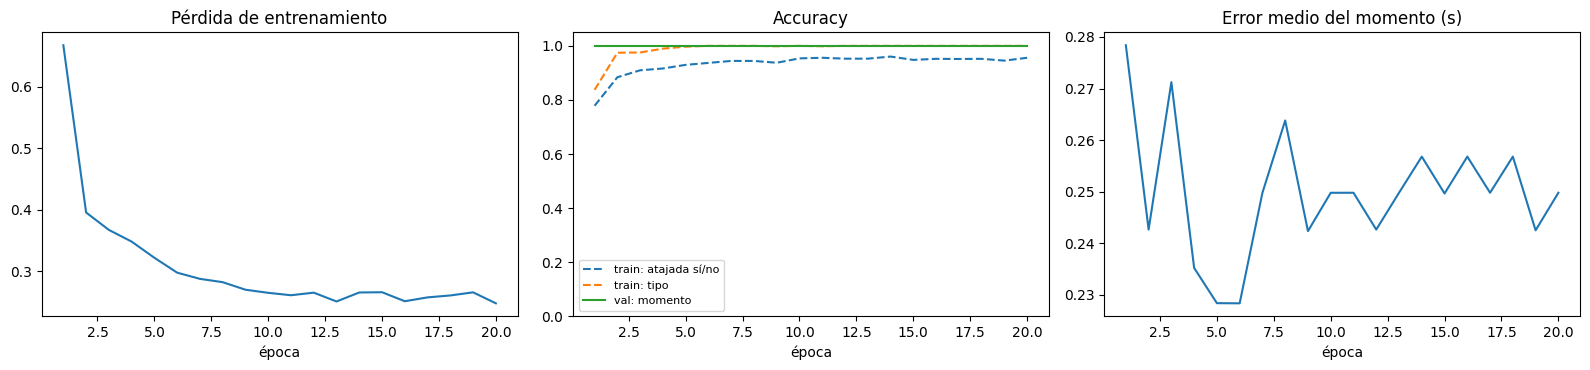

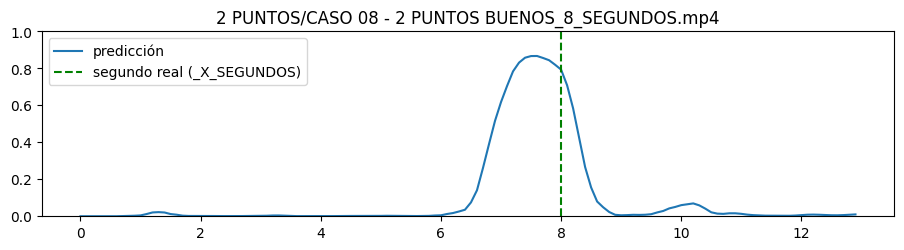

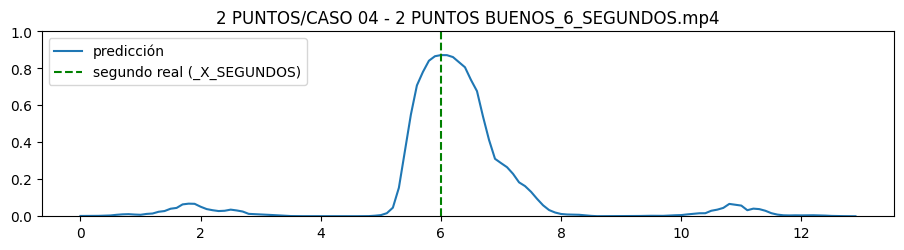

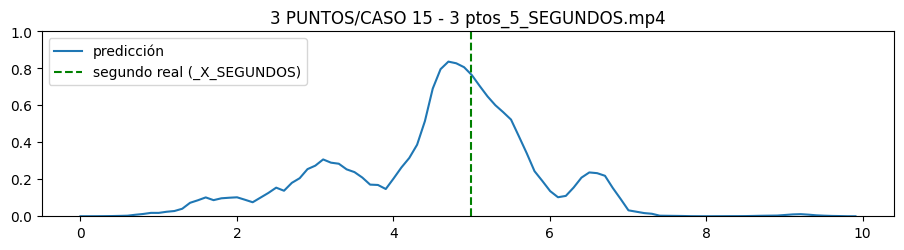

In [ ]:
# 2.7 Resultados en validación (con el mejor modelo)
ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck['state_dict'])
ev = evaluar(model, val_items)
print(f"ACCURACY GLOBAL (momento ±{TOLERANCIA_ACC_S:g}s y tipo correctos = puntaje correcto): {ev['acc_global']:.0%}")
print(f"Accuracy del momento: {ev['acc_momento']:.0%} | accuracy del tipo: {ev['acc_tipo']:.0%} | "
      f"error medio: {ev['mae']:.2f} s | dentro de 0,5 s: {ev['dentro_0.5s']:.0%}\n")
con_tipo = [f for f in ev['filas'] if f['tipo_real']]
if con_tipo and TIPOS_ENTRENADOS:
    print('Matriz de confusión del tipo (filas = real, columnas = predicho):')
    print(' ' * 12 + ''.join(f'{t[:10]:>11}' for t in TIPOS_ENTRENADOS))
    for tr in TIPOS_ENTRENADOS:
        print(f'{tr[:10]:<12}' + ''.join(f"{sum(1 for f in con_tipo if f['tipo_real'] == tr and f['tipo_pred'] == tp_):>11}" for tp_ in TIPOS_ENTRENADOS))
    print()
for f in ev['filas']:
    print(f"{f['video'][:55]:<55} real {f['t_real']:6.2f}s  pred {f['t_pred']:6.2f}s  err {f['error_s']:5.2f}s  "
          f"tipo {f['tipo_real']} -> {f['tipo_pred']}")

h = historial
E = [r['epoca'] for r in h]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(E, [r['loss'] for r in h]); ax[0].set_title('Pérdida de entrenamiento'); ax[0].set_xlabel('época')
ax[1].plot(E, [r['train_acc_det'] for r in h], '--', label='train: atajada sí/no')
ax[1].plot(E, [r['train_acc_tipo'] for r in h], '--', label='train: tipo')
ax[1].plot(E, [r['acc_momento'] for r in h], label='val: momento')
ax[1].set_ylim(0, 1.05); ax[1].set_title('Accuracy'); ax[1].set_xlabel('época'); ax[1].legend(fontsize=8)
ax[2].plot(E, [r['mae'] for r in h]); ax[2].set_title('Error medio del momento (s)'); ax[2].set_xlabel('época')
fig.tight_layout(); plt.show()

for it in val_items[:3]:
    frames = np.load(it['frames'], mmap_mode='r'); times = np.load(it['times'])
    ts, p, tp = curva_atajada(model, frames, times)
    plt.figure(figsize=(11, 2.4)); plt.plot(ts, suavizar(p), label='predicción')
    plt.axvline(it['t'], color='green', ls='--', label='segundo real (_X_SEGUNDOS)')
    plt.ylim(0, 1); plt.legend(loc='upper left'); plt.title(it['rel']); plt.show()

## 3. Analizar un video nuevo
Sube un video (no necesita `_X_SEGUNDOS` en el nombre). El notebook devuelve:
- **Puntaje** según la escala del reglamento y su justificación.
- **Curva de probabilidad** a lo largo del video con el instante detectado.
- **Cuadro exacto** de la atajada (imagen).
- **Video anotado**: borde rojo y rótulo «ATAJADA» en el momento, franja con la curva y, al final, **repetición en cámara lenta** con el cuadro congelado.

Todo queda guardado en `OUTPUT_DIR/resultados` de tu Drive.

In [ ]:
# 3.1 Cargar el modelo entrenado (útil si reiniciaste la sesión)
ck = cargar_modelo(CKPT_PATH)
print('Modelo cargado. Métricas de validación:', {k: round(v, 3) for k, v in ck['metricas'].items() if isinstance(v, float)})
print('Tipos que puede puntuar:', TIPOS_ENTRENADOS or 'ninguno (solo detecta el momento)')

In [ ]:
# 3.2 Subir y analizar un video
VIDEO_A_ANALIZAR = ''   # o pon aquí una ruta (p. ej. '/content/drive/MyDrive/rodeo/nuevo.mp4') para no subirlo
if not VIDEO_A_ANALIZAR:
    from google.colab import files
    subido = files.upload()
    VIDEO_A_ANALIZAR = next(iter(subido))
resultado = analizar_video(VIDEO_A_ANALIZAR)

In [ ]:
# 3.3 (Opcional) Descargar el video anotado a tu computador
from google.colab import files
files.download(f"{OUTPUT_DIR}/resultados/{Path(VIDEO_A_ANALIZAR).stem}_ANOTADO.mp4")

## 4. Descargar el modelo entrenado
Descarga a tu computador el archivo `atajada_r2plus1d.pt`. Incluye los pesos, los tipos de atajada, la escala de puntaje y la configuración con que se entrenó. También queda guardado en tu Drive, en `OUTPUT_DIR`.

In [ ]:
# 4.1 Método para descargar el modelo entrenado
def descargar_modelo(ruta=None):
    ruta = ruta or CKPT_PATH
    if not os.path.exists(ruta):
        raise FileNotFoundError(f'No existe {ruta}. Entrena el modelo (sección 2) o revisa OUTPUT_DIR.')
    ck = torch.load(ruta, map_location='cpu', weights_only=False)
    print(f'Modelo: {ruta}  ({os.path.getsize(ruta) / 1e6:.1f} MB)')
    print('Tipos que puntúa:', ck['tipos_entrenados'] or 'ninguno (solo detecta el momento)')
    print('Métricas de validación:', {k: round(v, 3) for k, v in ck['metricas'].items() if isinstance(v, float)})
    if IN_COLAB:
        from google.colab import files
        files.download(ruta)
    return ruta

descargar_modelo()

## 5. API del modelo
La API recibe **el video en bytes**, lo transforma para procesarlo (lo recodifica a H.264, corrige la orientación de los videos de celular y limita el ancho a 1280 px), detecta la atajada y responde:

- `puntaje`, `tipo_atajada`, `nombre_atajada`, `momento_segundos`, las confianzas y la justificación según el reglamento,
- **el video ya procesado** (borde rojo en la atajada, curva de probabilidad y repetición en cámara lenta), en base64,
- la imagen del cuadro exacto de la atajada, también en base64.

| Método | Ruta | Descripción |
|---|---|---|
| GET | `/salud` | Estado del servicio y escala de puntaje |
| POST | `/analizar` | Cuerpo = bytes del video (`application/octet-stream`), **o** formulario multipart con el campo `video` |

Parámetro `formato`: `json` (por defecto: resultado + video procesado en base64), `resumen` (solo el resultado, sin el video) o `video` (devuelve directamente el MP4 procesado, con el puntaje y el tipo en los headers `X-Puntaje`, `X-Tipo-Atajada`, `X-Momento-Segundos` y el resultado completo en `X-Resultado`, en base64).

Seguridad opcional: si defines `API_KEY`, cada petición debe enviar el header `X-API-Key`. Esto sirve para controlar quién usa la API si la vas a cobrar.

Pasos: 5.1 instala, 5.2 escribe el servidor `api_atajadas.py`, 5.3 arma un paquete Docker para publicarla en un servidor, 5.4 la levanta en Colab, 5.5 (opcional) le da una URL pública y 5.6 la prueba.

In [ ]:
# 5.1 Instalar dependencias de la API
!pip -q install fastapi "uvicorn[standard]" python-multipart requests
API_DIR = '/content/atajadas_api'
os.makedirs(f'{API_DIR}/modelo', exist_ok=True)
print('Carpeta de la API:', API_DIR)

In [ ]:
%%writefile /content/atajadas_api/api_atajadas.py
# api_atajadas.py — API del detector de atajadas (generado por el notebook detector_atajadas_rodeo.ipynb)
# Ejecutar:  MODEL_PATH=modelo/atajada_r2plus1d.pt uvicorn api_atajadas:app --host 0.0.0.0 --port 8000
import os
os.environ.setdefault('MPLBACKEND', 'Agg')

import os, re, io, sys, json, math, time, random, hashlib, subprocess, unicodedata, base64, tempfile, shutil, threading
from pathlib import Path
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------- Video / modelo ----------
TARGET_FPS = 10        # cuadros por segundo que ve el modelo
CLIP_LEN = 16          # cuadros por clip (16 a 10 fps = 1,6 s de movimiento)
FRAME_SIZE = 128       # tamaño al que se reduce cada cuadro
CROP_SIZE = 112        # recorte de entrada a la red
TYPE_RADIUS_S = 0.4    # radio (s) alrededor del momento usado para decidir el tipo de atajada

# ---------- Análisis de videos ----------
DET_THRESHOLD = 0.35   # probabilidad mínima para afirmar que hay atajada
HIGHLIGHT_S = 0.6      # segundos antes/después del momento que se marcan en rojo
SLOWMO_WINDOW_S = 1.5  # repetición en cámara lenta: ± segundos alrededor de la atajada
SLOWMO_FACTOR = 4      # 4 = velocidad 1/4
FREEZE_S = 1.5         # congelar el cuadro exacto de la atajada

KB_PATH = os.environ.get('KB_PATH', '')  # opcional: ruta al skills.md; si está vacío se busca en /content y en MyDrive
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
VIDEO_EXT = {'.mp4', '.mov', '.avi', '.mkv', '.m4v', '.webm', '.mpg', '.mpeg', '.3gp', '.mts'}

# 1.3 Base de conocimiento: escala de puntaje de atajadas (compendio FEROCHI §6.1)
REGLAS = {
    'costilla':  {'puntos': 4, 'nombre': 'Atajada de costilla libre (de íjar)'},
    'paleta':    {'puntos': 3, 'nombre': 'Atajada de paleta libre (de mitad)'},
    'cogote':    {'puntos': 2, 'nombre': 'Atajada de cogote libre'},
    'envoltura': {'puntos': 0, 'nombre': 'Envoltura (no se define la atajada)'},
}
TIPOS = list(REGLAS)
FUENTE_REGLAS = 'Compendio Normativo FEROCHI 2026-2027, §6.1 Escala de Valoración de Atajadas'

def sin_tildes(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

PALABRAS_TIPO = {
    'costilla':  ['costilla', 'ijar'],
    'paleta':    ['paleta', 'mitad'],
    'cogote':    ['cogote', 'pescuezo'],
    'envoltura': ['envoltura', 'envuelta', 'envolvio'],
}

def cargar_reglas_md(path):
    # Lee líneas tipo '**Atajada de Costilla Libre (de íjar)**: 4 puntos buenos.' y actualiza REGLAS
    texto = Path(path).read_text(encoding='utf-8')
    n = 0
    for m in re.finditer(r'\*\*([^*]+)\*\*\s*:\s*(\d+)\s*punto', texto):
        etiqueta, pts = m.group(1).strip(), int(m.group(2))
        e = sin_tildes(etiqueta).lower()
        for tipo, claves in PALABRAS_TIPO.items():
            if any(k in e for k in claves):
                REGLAS[tipo] = {'puntos': pts, 'nombre': etiqueta}
                n += 1
                break
    return n

_kb = KB_PATH or next((p for p in ['/content/skills.md', '/content/drive/MyDrive/skills.md'] if os.path.exists(p)), '')
if _kb and os.path.exists(_kb):
    print(f'Base de conocimiento leída de {_kb}: {cargar_reglas_md(_kb)} reglas de atajada.')
else:
    print('Usando la escala de atajadas del compendio incluida en el notebook.')
for t in TIPOS:
    print(f"  {REGLAS[t]['nombre']:<40} -> {REGLAS[t]['puntos']} pts")

# 1.4 Utilidades de video
MEAN = np.array([0.43216, 0.394666, 0.37645], np.float32)   # normalización Kinetics
STD = np.array([0.22803, 0.22145, 0.216989], np.float32)

def leer_video(path, fps_obj=None, size=None):
    # Devuelve cuadros RGB (N,size,size,3) muestreados a fps_obj, sus tiempos (s) y la duración total
    fps_obj = fps_obj or TARGET_FPS; size = size or FRAME_SIZE
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps < 1:
        fps = 30.0
    frames, times = [], []
    i, prox, paso = 0, 0.0, 1.0 / fps_obj
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        t = i / fps
        if t + 1e-6 >= prox:
            fr = cv2.resize(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_AREA)
            frames.append(fr); times.append(t)
            while prox <= t + 1e-6:
                prox += paso
        i += 1
    cap.release()
    if not frames:
        return np.zeros((0, size, size, 3), np.uint8), np.zeros(0, np.float32), 0.0
    return np.stack(frames), np.array(times, np.float32), i / fps

def indices_clip(n, c, L=None):
    # índices de un clip de L cuadros centrado en c (se repiten los bordes)
    L = L or CLIP_LEN
    return np.clip(np.arange(c - L // 2, c - L // 2 + L), 0, n - 1)

def preparar_clip(clip, train=False):
    # (L,H,W,3) uint8 -> tensor (3,L,CROP,CROP) normalizado; con aumentos si train
    L, H, W, _ = clip.shape
    if train:
        y0 = np.random.randint(0, H - CROP_SIZE + 1); x0 = np.random.randint(0, W - CROP_SIZE + 1)
    else:
        y0 = (H - CROP_SIZE) // 2; x0 = (W - CROP_SIZE) // 2
    x = clip[:, y0:y0 + CROP_SIZE, x0:x0 + CROP_SIZE].astype(np.float32) / 255.0
    if train:
        if np.random.rand() < 0.5:          # atajadas hacia ambos lados de la medialuna
            x = x[:, :, ::-1]
        x = np.clip(x * np.random.uniform(0.8, 1.2) + np.random.uniform(-0.08, 0.08), 0, 1)
    x = (x - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(3, 0, 1, 2)))

# 1.5 Modelo: red de video 3D que aprende el movimiento
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights

class AtajadaNet(nn.Module):
    # det  -> probabilidad de que el centro del clip sea el instante de la atajada
    # tipo -> costilla / paleta / cogote / envoltura
    def __init__(self, n_tipos, pretrained=True):
        super().__init__()
        self.backbone = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1 if pretrained else None)
        feat = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.drop = nn.Dropout(0.4)
        self.det = nn.Linear(feat, 1)
        self.tipo = nn.Linear(feat, n_tipos)

    def forward(self, x):
        f = self.drop(self.backbone(x))
        return self.det(f).squeeze(1), self.tipo(f)

@torch.no_grad()
def curva_atajada(model, frames, times, stride=1, batch=32):
    # Recorre todo el video con una ventana deslizante y devuelve la probabilidad de atajada en cada instante
    model.eval()
    n = len(frames)
    centros = np.arange(0, n, stride)
    P, T = [], []
    for s in range(0, len(centros), batch):
        x = torch.stack([preparar_clip(np.asarray(frames[indices_clip(n, c)])) for c in centros[s:s + batch]]).to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')):
            det, tip = model(x)
        P.append(torch.sigmoid(det.float()).cpu().numpy())
        T.append(torch.softmax(tip.float(), 1).cpu().numpy())
    return times[centros], np.concatenate(P), np.concatenate(T)

def suavizar(p, k=3):
    if len(p) < k:
        return p
    return np.convolve(np.pad(p, k // 2, mode='edge'), np.ones(k) / k, mode='valid')

def localizar(ts, p, tp, radio=None):
    # Momento de máxima probabilidad + probabilidades de tipo promediadas alrededor de ese momento
    radio = radio or TYPE_RADIUS_S
    ps = suavizar(p)
    j = int(np.argmax(ps))
    cerca = np.abs(ts - ts[j]) <= radio
    w = ps[cerca][:, None]
    tipo_prob = (tp[cerca] * w).sum(0) / max(float(w.sum()), 1e-6)
    return {'t': float(ts[j]), 'prob': float(ps[j]), 'tipo_prob': tipo_prob, 'curva': ps}

def cargar_modelo(ckpt_path):
    # Carga el modelo entrenado y la configuración con que se entrenó (tipos, reglas, fps, tamaños)
    global model, TIPOS, TIPOS_ENTRENADOS, TARGET_FPS, CLIP_LEN, FRAME_SIZE, CROP_SIZE
    ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    TIPOS = ck['tipos']; TIPOS_ENTRENADOS = ck['tipos_entrenados']; REGLAS.update(ck['reglas'])
    TARGET_FPS, CLIP_LEN, FRAME_SIZE, CROP_SIZE = (ck['config'][k] for k in ('TARGET_FPS', 'CLIP_LEN', 'FRAME_SIZE', 'CROP_SIZE'))
    model = AtajadaNet(len(TIPOS), pretrained=False).to(DEVICE)
    model.load_state_dict(ck['state_dict']); model.eval()
    return ck

# 1.6 Análisis de un video: puntaje + video anotado con el momento de la atajada
import matplotlib.pyplot as plt

def _txt(img, texto, org, escala, color, grosor=2, fondo=(0, 0, 0)):
    texto = sin_tildes(texto)
    (w, h), b = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, grosor)
    x, y = org
    cv2.rectangle(img, (x - 6, y - h - 8), (x + w + 6, y + b + 4), fondo, -1)
    cv2.putText(img, texto, (x, y), cv2.FONT_HERSHEY_SIMPLEX, escala, color, grosor, cv2.LINE_AA)

def _franja(W, alto, ts, curva, dur, t_at):
    img = np.full((alto, W, 3), 30, np.uint8)
    X = lambda t: int(np.clip(t / max(dur, 1e-6) * (W - 1), 0, W - 1))
    Y = lambda p: int(alto - 8 - p * (alto - 28))
    cv2.line(img, (0, Y(DET_THRESHOLD)), (W - 1, Y(DET_THRESHOLD)), (90, 90, 90), 1)
    pts = np.array([[X(t), Y(p)] for t, p in zip(ts, curva)], np.int32)
    if len(pts) > 1:
        cv2.polylines(img, [pts], False, (0, 200, 255), 2, cv2.LINE_AA)
    if t_at is not None:
        cv2.line(img, (X(t_at), 0), (X(t_at), alto - 1), (0, 0, 255), 2)
    _txt(img, 'Prob. de atajada', (8, 18), 0.45, (220, 220, 220), 1, fondo=(30, 30, 30))
    return img, X

def anotar_video(path, res, out_path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if fps and fps == fps and fps >= 1 else 30.0
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    esc = max(W / 1280, 0.45)
    alto_f = max(int(90 * esc), 60)
    t_at = res['t'] if res['detectada'] else None
    franja, X = _franja(W, alto_f, res['ts'], res['curva'], res['duracion'], t_at)
    if not res['detectada']:
        titulo = 'Sin atajada clara'
    elif res['puntos'] is None:
        titulo = 'Atajada detectada (tipo no entrenado)'
    else:
        titulo = f"{res['nombre']}: {res['puntos']} pts"
    g = max(1, int(2 * esc))

    def componer(fr, t, repeticion=False):
        img = fr.copy()
        cerca = res['detectada'] and abs(t - res['t']) <= HIGHLIGHT_S
        if cerca:
            cv2.rectangle(img, (0, 0), (W - 1, H - 1), (0, 0, 255), max(4, int(12 * esc)))
            _txt(img, f"ATAJADA  t = {res['t']:.1f} s", (int(20 * esc), H - int(30 * esc)), 1.3 * esc, (255, 255, 255), max(2, int(3 * esc)), fondo=(0, 0, 200))
        _txt(img, titulo, (int(20 * esc), int(45 * esc)), 0.9 * esc, (255, 255, 255), g)
        _txt(img, f't = {t:5.2f} s', (int(20 * esc), int(90 * esc)), 0.7 * esc, (200, 200, 200), g)
        if repeticion:
            _txt(img, f'REPETICION 1/{SLOWMO_FACTOR}', (W - int(330 * esc), int(45 * esc)), 0.8 * esc, (0, 255, 255), g)
        f = franja.copy()
        cv2.line(f, (X(t), 0), (X(t), alto_f - 1), (255, 255, 255), 1)
        return np.vstack([img, f])

    tmp = out_path + '.tmp.mp4'
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H + alto_f))
    clave, mejor, i = None, 1e9, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        t = i / fps
        lienzo = componer(fr, t)
        vw.write(lienzo)
        if t_at is not None and abs(t - t_at) < mejor:
            mejor, clave = abs(t - t_at), lienzo.copy()
        i += 1
    # Repetición en cámara lenta con cuadro congelado en el instante exacto
    if t_at is not None:
        j = max(0, int((t_at - SLOWMO_WINDOW_S) * fps))
        cap.set(cv2.CAP_PROP_POS_FRAMES, j)
        congelado = False
        while j / fps <= t_at + SLOWMO_WINDOW_S:
            ok, fr = cap.read()
            if not ok:
                break
            lienzo = componer(fr, j / fps, repeticion=True)
            reps = SLOWMO_FACTOR
            if not congelado and j / fps >= t_at - 0.5 / fps:
                reps += int(FREEZE_S * fps); congelado = True
            for _ in range(reps):
                vw.write(lienzo)
            j += 1
    cap.release(); vw.release()
    try:   # H.264 para que se vea en el navegador
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', tmp, '-vf', 'scale=trunc(iw/2)*2:trunc(ih/2)*2',
                        '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', '-crf', '23', out_path], check=True)
        os.remove(tmp)
    except Exception as e:
        print('ffmpeg no disponible, se deja el video en mp4v:', e)
        os.replace(tmp, out_path)
    return clave

def analizar_video(path, mostrar=True, out_dir=None):
    frames, times, dur = leer_video(path)
    if len(frames) == 0:
        raise ValueError(f'No se pudo leer el video: {path}')
    ts, p, tp = curva_atajada(model, frames, times)
    loc = localizar(ts, p, tp)
    detectada = loc['prob'] >= DET_THRESHOLD
    tipo, conf_tipo, probs_tipo = None, None, {}
    if TIPOS_ENTRENADOS:
        idx = [TIPOS.index(t) for t in TIPOS_ENTRENADOS]
        pt = loc['tipo_prob'][idx]; pt = pt / max(pt.sum(), 1e-9)
        probs_tipo = {t: float(v) for t, v in zip(TIPOS_ENTRENADOS, pt)}
        tipo = max(probs_tipo, key=probs_tipo.get); conf_tipo = probs_tipo[tipo]
    res = {
        'video': str(path), 'duracion': float(dur), 'detectada': bool(detectada),
        't': loc['t'], 'prob': loc['prob'], 'ts': ts, 'curva': loc['curva'],
        'tipo': tipo if detectada else None, 'conf_tipo': conf_tipo, 'probs_tipo': probs_tipo,
        'nombre': REGLAS[tipo]['nombre'] if (detectada and tipo) else None,
        'puntos': (REGLAS[tipo]['puntos'] if tipo else None) if detectada else 0,
    }
    base = Path(path).stem
    out_dir = out_dir or f'{OUTPUT_DIR}/resultados'
    os.makedirs(out_dir, exist_ok=True)
    out_video = f'{out_dir}/{base}_ANOTADO.mp4'
    clave = anotar_video(path, res, out_video)

    # Justificación
    lineas = []
    if not detectada:
        lineas.append(f"No se detectó una atajada clara (máxima probabilidad {loc['prob']:.0%} < umbral {DET_THRESHOLD:.0%}).")
        lineas.append('Puntaje asignado por atajada: 0.')
    else:
        lineas.append(f"Momento de la atajada: {res['t']:.1f} s (confianza de detección {res['prob']:.0%}).")
        if tipo:
            lineas.append(f"Clasificación: {res['nombre']} -> {res['puntos']} puntos buenos (confianza {conf_tipo:.0%}).")
            lineas.append(f"Fundamento: {FUENTE_REGLAS}: «{res['nombre']}» = {res['puntos']} puntos buenos.")
            lineas.append('Probabilidad por tipo: ' + ', '.join(f"{t} {v:.0%}" for t, v in sorted(probs_tipo.items(), key=lambda kv: -kv[1])))
            if conf_tipo < 0.5:
                lineas.append('⚠ Confianza baja en el tipo de atajada: revisa la repetición en cámara lenta.')
        else:
            lineas.append('El modelo no fue entrenado con el tipo de atajada (carpetas sin costilla/paleta/cogote/envoltura), no puede asignar puntaje.')
    lineas.append('Nota: se evalúa solo la atajada; la salida del apiñadero (+1) y las faltas (tijera, ayuda, etc.) no se califican aquí.')
    res['justificacion'] = '\n'.join(lineas)

    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(ts, loc['curva'], color='tab:orange', label='prob. de atajada')
    ax.axhline(DET_THRESHOLD, color='gray', ls='--', lw=1, label='umbral')
    if detectada:
        ax.axvline(res['t'], color='red', lw=2, label=f"atajada {res['t']:.1f} s")
        ax.axvspan(res['t'] - HIGHLIGHT_S, res['t'] + HIGHLIGHT_S, color='red', alpha=0.12)
    ax.set_xlabel('segundos'); ax.set_ylim(0, 1); ax.legend(loc='upper left'); ax.set_title(base)
    fig.tight_layout(); fig.savefig(f'{out_dir}/{base}_curva.png', dpi=110)
    img_path = None
    if clave is not None:
        img_path = f'{out_dir}/{base}_momento_atajada.jpg'
        cv2.imwrite(img_path, clave)
    res['archivos'] = {'video': out_video, 'imagen': img_path, 'curva': f'{out_dir}/{base}_curva.png'}
    guardable = {k: v for k, v in res.items() if k not in ('ts', 'curva')}
    Path(f'{out_dir}/{base}_resultado.json').write_text(json.dumps(guardable, ensure_ascii=False, indent=2))

    if mostrar:
        from IPython.display import display, HTML, Image as IPImage
        print('=' * 70)
        print(f"PUNTAJE DE LA ATAJADA: {res['puntos'] if res['puntos'] is not None else 's/d'}")
        print('=' * 70)
        print(res['justificacion'])
        plt.show()
        if clave is not None:
            print('Cuadro exacto de la atajada:')
            display(IPImage(filename=f'{out_dir}/{base}_momento_atajada.jpg', width=720))
        if os.path.getsize(out_video) < 45 * 1024 * 1024:
            b64 = base64.b64encode(open(out_video, 'rb').read()).decode()
            display(HTML(f'<video width="760" controls src="data:video/mp4;base64,{b64}"></video>'))
        else:
            print('Video anotado (muy pesado para mostrarlo aquí):', out_video)
        print('Archivos guardados en:', out_dir)
    else:
        plt.close(fig)
    return res

# =============================== API ===============================
from typing import Optional
from fastapi import FastAPI, Request, HTTPException, Query, Header
from fastapi.responses import JSONResponse, Response
from fastapi.middleware.cors import CORSMiddleware
from starlette.concurrency import run_in_threadpool

OUTPUT_DIR = tempfile.gettempdir()
MODEL_PATH = os.environ.get('MODEL_PATH', str(Path(__file__).resolve().parent / 'modelo' / 'atajada_r2plus1d.pt'))
API_KEY = os.environ.get('API_KEY', '')                       # si se define, se exige el header X-API-Key
MAX_MB = float(os.environ.get('MAX_MB', '300'))               # tamaño máximo del video recibido
MAX_DURACION_S = float(os.environ.get('MAX_DURACION_S', '600'))
MAX_ANCHO = int(os.environ.get('MAX_ANCHO', '1280'))          # ancho máximo tras normalizar el video
DET_THRESHOLD = float(os.environ.get('DET_THRESHOLD', DET_THRESHOLD))

CK = cargar_modelo(MODEL_PATH)
_lock = threading.Lock()                                      # una inferencia a la vez en la GPU


def normalizar_video(data, nombre, carpeta):
    # Bytes recibidos -> MP4 H.264 legible por OpenCV, con la orientación corregida y ancho <= MAX_ANCHO
    ext = Path(nombre or '').suffix.lower()
    crudo = os.path.join(carpeta, 'entrada' + (ext if ext in VIDEO_EXT else '.bin'))
    with open(crudo, 'wb') as f:
        f.write(data)
    destino = os.path.join(carpeta, 'video.mp4')
    try:
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', crudo, '-an',
                        '-vf', f"scale='trunc(min({MAX_ANCHO},iw)/2)*2':-2",
                        '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', '-crf', '20', destino],
                       check=True, timeout=900)
    except FileNotFoundError:            # sin ffmpeg instalado: se intenta leer el archivo tal cual
        destino = crudo
    except (subprocess.CalledProcessError, subprocess.TimeoutExpired):
        raise ValueError('El archivo recibido no es un video válido o su formato no es compatible.')
    cap = cv2.VideoCapture(destino)
    ok, _ = cap.read()
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    n = cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0
    cap.release()
    if not ok:
        raise ValueError('No se pudo leer ningún cuadro del video.')
    if fps > 0 and n / fps > MAX_DURACION_S:
        raise ValueError(f'El video dura {n / fps:.0f} s; el máximo permitido es {MAX_DURACION_S:.0f} s.')
    return destino


def procesar_video_bytes(data, nombre='video.mp4'):
    # Función principal: bytes de un video -> (resultado con puntaje y tipo, video procesado, imagen de la atajada)
    t0 = time.time()
    with tempfile.TemporaryDirectory() as td:
        path = normalizar_video(data, nombre, td)
        with _lock:
            res = analizar_video(path, mostrar=False, out_dir=td)
        video = Path(res['archivos']['video']).read_bytes()
        img = Path(res['archivos']['imagen']).read_bytes() if res['archivos']['imagen'] else None
    resultado = {
        'detectada': bool(res['detectada']),
        'puntaje': res['puntos'],
        'tipo_atajada': res['tipo'],
        'nombre_atajada': res['nombre'],
        'momento_segundos': round(float(res['t']), 2) if res['detectada'] else None,
        'confianza_deteccion': round(float(res['prob']), 4),
        'confianza_tipo': round(float(res['conf_tipo']), 4) if (res['detectada'] and res['conf_tipo'] is not None) else None,
        'probabilidades_tipo': {k: round(float(v), 4) for k, v in res['probs_tipo'].items()},
        'justificacion': res['justificacion'],
        'fundamento': FUENTE_REGLAS,
        'duracion_video_s': round(float(res['duracion']), 2),
        'tiempo_proceso_s': round(time.time() - t0, 2),
    }
    return resultado, video, img


app = FastAPI(title='API de atajadas – Rodeo chileno', version='1.0',
              description='Recibe un video (bytes) de una carrera, detecta la atajada y devuelve puntaje, tipo y video procesado.')
app.add_middleware(CORSMiddleware, allow_origins=os.environ.get('CORS_ORIGINS', '*').split(','),
                   allow_methods=['*'], allow_headers=['*'],
                   expose_headers=['X-Puntaje', 'X-Tipo-Atajada', 'X-Momento-Segundos', 'X-Detectada', 'X-Resultado'])


def _verificar_clave(x_api_key):
    if API_KEY and x_api_key != API_KEY:
        raise HTTPException(401, 'API key inválida o ausente (header X-API-Key).')


@app.get('/salud')
def salud():
    return {'estado': 'ok', 'dispositivo': DEVICE, 'tipos_puntuables': TIPOS_ENTRENADOS,
            'escala': {t: REGLAS[t] for t in TIPOS}, 'umbral_deteccion': DET_THRESHOLD,
            'metricas_validacion': {k: v for k, v in CK.get('metricas', {}).items() if isinstance(v, (int, float))}}


@app.post('/analizar')
async def analizar(request: Request,
                   formato: str = Query('json', description='json | resumen | video'),
                   x_api_key: Optional[str] = Header(None),
                   x_filename: Optional[str] = Header(None)):
    _verificar_clave(x_api_key)
    if formato not in ('json', 'resumen', 'video'):
        raise HTTPException(400, "formato debe ser 'json', 'resumen' o 'video'.")
    if request.headers.get('content-type', '').lower().startswith('multipart/form-data'):
        form = await request.form()
        archivo = form.get('video') or next((v for v in form.values() if hasattr(v, 'read')), None)
        if archivo is None or not hasattr(archivo, 'read'):
            raise HTTPException(400, "Envía el video en el campo 'video' del formulario.")
        data, nombre = await archivo.read(), (archivo.filename or 'video.mp4')
    else:
        data, nombre = await request.body(), (x_filename or 'video.mp4')
    if not data:
        raise HTTPException(400, 'No se recibió ningún video (cuerpo vacío).')
    if len(data) > MAX_MB * 1024 * 1024:
        raise HTTPException(413, f'El video supera el máximo de {MAX_MB:.0f} MB.')
    try:
        resultado, video, img = await run_in_threadpool(procesar_video_bytes, data, nombre)
    except ValueError as e:
        raise HTTPException(422, str(e))

    base = re.sub(r'[^A-Za-z0-9_.-]+', '_', sin_tildes(Path(nombre).stem)) or 'video'
    if formato == 'video':
        cab = {'X-Puntaje': '' if resultado['puntaje'] is None else str(resultado['puntaje']),
               'X-Tipo-Atajada': resultado['tipo_atajada'] or '',
               'X-Momento-Segundos': '' if resultado['momento_segundos'] is None else str(resultado['momento_segundos']),
               'X-Detectada': str(resultado['detectada']).lower(),
               'X-Resultado': base64.b64encode(json.dumps(resultado, ensure_ascii=False).encode()).decode(),
               'Content-Disposition': f'attachment; filename="{base}_ANOTADO.mp4"'}
        return Response(video, media_type='video/mp4', headers=cab)
    if formato == 'json':
        resultado['video_anotado'] = {'nombre': f'{base}_ANOTADO.mp4', 'content_type': 'video/mp4',
                                      'base64': base64.b64encode(video).decode()}
        resultado['imagen_atajada'] = ({'nombre': f'{base}_momento_atajada.jpg', 'content_type': 'image/jpeg',
                                        'base64': base64.b64encode(img).decode()} if img else None)
    return JSONResponse(resultado)


if __name__ == '__main__':
    import uvicorn
    uvicorn.run(app, host='0.0.0.0', port=int(os.environ.get('PORT', '8000')))

In [ ]:
# 5.3 Paquete para publicar la API en cualquier servidor (Docker) y descargarlo
DESCARGAR_PAQUETE = True
shutil.copy(CKPT_PATH, f'{API_DIR}/modelo/atajada_r2plus1d.pt')
Path(f'{API_DIR}/requirements.txt').write_text('''numpy
opencv-python-headless
matplotlib
fastapi
uvicorn[standard]
python-multipart
''')
Path(f'{API_DIR}/Dockerfile').write_text('''FROM python:3.11-slim
RUN apt-get update && apt-get install -y --no-install-recommends ffmpeg && rm -rf /var/lib/apt/lists/*
WORKDIR /app
COPY requirements.txt .
# Para servidor con GPU, cambia la línea siguiente por: pip install torch torchvision
RUN pip install --no-cache-dir torch torchvision --index-url https://download.pytorch.org/whl/cpu && \\
    pip install --no-cache-dir -r requirements.txt
COPY api_atajadas.py .
COPY modelo/ modelo/
ENV PORT=8000
EXPOSE 8000
CMD ["sh", "-c", "uvicorn api_atajadas:app --host 0.0.0.0 --port ${PORT}"]
''')
Path(f'{API_DIR}/README.md').write_text('''# API de atajadas

## Ejecutar con Docker
    docker build -t atajadas-api .
    docker run -p 8000:8000 -e API_KEY=mi_clave atajadas-api

## Ejecutar sin Docker (requiere ffmpeg)
    pip install torch torchvision -r requirements.txt
    uvicorn api_atajadas:app --host 0.0.0.0 --port 8000

## Uso
    # bytes del video en el cuerpo
    curl -X POST "http://localhost:8000/analizar" -H "Content-Type: application/octet-stream" \\
         -H "X-API-Key: mi_clave" --data-binary @carrera.mp4

    # formulario multipart
    curl -X POST "http://localhost:8000/analizar?formato=resumen" -H "X-API-Key: mi_clave" -F "video=@carrera.mp4"

    # recibir directamente el MP4 procesado (puntaje y tipo en los headers)
    curl -X POST "http://localhost:8000/analizar?formato=video" -H "X-API-Key: mi_clave" \\
         --data-binary @carrera.mp4 -D headers.txt -o carrera_ANOTADO.mp4

Documentación interactiva: http://localhost:8000/docs

Variables de entorno: MODEL_PATH, API_KEY, MAX_MB (300), MAX_DURACION_S (600), MAX_ANCHO (1280), DET_THRESHOLD, CORS_ORIGINS, PORT.
''')
zip_path = shutil.make_archive(f'{OUTPUT_DIR}/atajadas_api', 'zip', API_DIR)
print('Paquete listo:', zip_path, f'({os.path.getsize(zip_path) / 1e6:.1f} MB)')
for f in sorted(Path(API_DIR).rglob('*')):
    if f.is_file():
        print('  ', f.relative_to(API_DIR))
if IN_COLAB and DESCARGAR_PAQUETE:
    from google.colab import files
    files.download(zip_path)

In [ ]:
# 5.4 Levantar la API dentro de Colab
import importlib, requests, uvicorn
API_KEY = ''        # opcional: si pones una clave, la API exigirá el header X-API-Key
PUERTO = 8000
os.environ['MODEL_PATH'] = CKPT_PATH
os.environ['API_KEY'] = API_KEY
if API_DIR not in sys.path:
    sys.path.insert(0, API_DIR)
import api_atajadas
importlib.reload(api_atajadas)

if 'servidor_api' in globals():          # si se vuelve a ejecutar la celda, se detiene el servidor anterior
    servidor_api.should_exit = True
    hilo_api.join(timeout=15)
servidor_api = uvicorn.Server(uvicorn.Config(api_atajadas.app, host='0.0.0.0', port=PUERTO, log_level='warning'))
hilo_api = threading.Thread(target=servidor_api.run, daemon=True)
hilo_api.start()

URL_LOCAL = f'http://127.0.0.1:{PUERTO}'
for _ in range(120):
    try:
        r = requests.get(f'{URL_LOCAL}/salud', timeout=2)
        if r.ok:
            break
    except requests.exceptions.ConnectionError:
        pass
    time.sleep(1)
print('API activa en', URL_LOCAL)
print(json.dumps(r.json(), ensure_ascii=False, indent=2))

In [ ]:
# 5.5 (Opcional) URL pública temporal con Cloudflare Tunnel, sin crear cuenta
# Sirve para probar desde otra app o computador mientras la sesión de Colab siga abierta.
# Para un servicio permanente usa el paquete Docker de la celda 5.3 en un servidor.
CLOUDFLARED = '/content/cloudflared'
if not os.path.exists(CLOUDFLARED):
    subprocess.run(['wget', '-q', '-O', CLOUDFLARED,
                    'https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64'], check=True)
    os.chmod(CLOUDFLARED, 0o755)
if 'tunel' in globals() and tunel.poll() is None:
    tunel.terminate()
tunel = subprocess.Popen([CLOUDFLARED, 'tunnel', '--no-autoupdate', '--url', f'http://127.0.0.1:{PUERTO}'],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
URL_PUBLICA = None
_url_lista = threading.Event()

def _leer_tunel():
    global URL_PUBLICA
    for linea in tunel.stdout:
        m = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', linea)
        if m and not URL_PUBLICA:
            URL_PUBLICA = m.group(0)
            _url_lista.set()

threading.Thread(target=_leer_tunel, daemon=True).start()
_url_lista.wait(60)
if URL_PUBLICA:
    clave = f' -H "X-API-Key: {API_KEY}"' if API_KEY else ''
    print('URL pública:', URL_PUBLICA)
    print('Documentación interactiva:', URL_PUBLICA + '/docs')
    print('\nEjemplo:')
    print(f'curl -X POST "{URL_PUBLICA}/analizar?formato=resumen"{clave} -H "Content-Type: application/octet-stream" --data-binary @carrera.mp4')
else:
    print('No se obtuvo la URL pública. Vuelve a ejecutar la celda.')

In [ ]:
# 5.6 Probar la API: enviar un video en bytes y recibir puntaje, tipo y el video procesado
VIDEO_PRUEBA = globals().get('VIDEO_A_ANALIZAR', '')   # por defecto, el video de la sección 3
if not VIDEO_PRUEBA or not os.path.exists(VIDEO_PRUEBA):
    from google.colab import files
    VIDEO_PRUEBA = next(iter(files.upload()))

datos = Path(VIDEO_PRUEBA).read_bytes()                  # <- el video en bytes
cab = {'Content-Type': 'application/octet-stream', 'X-Filename': sin_tildes(Path(VIDEO_PRUEBA).name)}
if API_KEY:
    cab['X-API-Key'] = API_KEY
r = requests.post(f'{URL_LOCAL}/analizar', data=datos, headers=cab, timeout=1800)
r.raise_for_status()
respuesta = r.json()

print(json.dumps({k: v for k, v in respuesta.items() if k not in ('video_anotado', 'imagen_atajada')}, ensure_ascii=False, indent=2))
os.makedirs(f'{OUTPUT_DIR}/resultados', exist_ok=True)
salida = f"{OUTPUT_DIR}/resultados/{Path(VIDEO_PRUEBA).stem}_API_ANOTADO.mp4"
Path(salida).write_bytes(base64.b64decode(respuesta['video_anotado']['base64']))
print('\nVideo procesado recibido de la API y guardado en:', salida)
from IPython.display import display, HTML
display(HTML(f'<video width="760" controls src="data:video/mp4;base64,{respuesta["video_anotado"]["base64"]}"></video>'))

### Cómo consumir la API desde otra aplicación (Python)
```python
import requests, base64
URL = 'https://TU-URL'          # URL_PUBLICA (5.5) o la de tu servidor
with open('carrera.mp4', 'rb') as f:
    datos = f.read()            # video en bytes
r = requests.post(f'{URL}/analizar', data=datos,
                  headers={'Content-Type': 'application/octet-stream', 'X-API-Key': 'mi_clave'})
res = r.json()
print(res['puntaje'], res['tipo_atajada'], res['momento_segundos'])
open('carrera_ANOTADO.mp4', 'wb').write(base64.b64decode(res['video_anotado']['base64']))
```